# Fixed Income Sensitivities: Duration, Convexity, DV01, KRD + Curve PCA

"What is the duration?" is the first question about any bond portfolio, and the answer is never enough on its own, because real yield curves rarely move in parallel. This notebook computes the full set of interest-rate sensitivities for a real portfolio and checks how well each one predicts the P&L of realistic curve moves.

**What it does.** It computes the full set of interest-rate sensitivities of a USD 1 billion MDB-style treasury portfolio built from real bonds, and checks how well each measure predicts the P&L of realistic curve scenarios.

**Data.** Live bond-level holdings of four iShares ETFs (Treasuries, agencies, sub-sovereigns, banks, corporates), today's Treasury par curve (U.S. Treasury) and 10 years of daily Treasury yields (FRED).

**Methods.** Yield-based and curve-based (effective) duration and convexity, DV01, key-rate durations, and PCA of curve moves to build level, slope and curvature scenarios. Full revaluation is compared with first- and second-order Taylor approximations.

**Key output.** A sensitivity report by bond and by sleeve, a key-rate risk heatmap, a scenario P&L table (parallel, twist, butterfly, PCA and historical), and a map of where the duration approximation breaks down.

## 1. Why a risk officer needs more than one number

"What is the duration?" is the first question about any bond portfolio, and the answer is never complete on its own:

- **Duration** gives the loss for a small *parallel* shift. Real curves rarely move in parallel.
- **Convexity** corrects for the curvature of the price–yield relationship, which matters for large moves.
- **Key-rate durations** split the risk along the curve, so a steepener or a twist can be priced.
- **PCA** tells us which curve shapes are actually likely, so stress scenarios are realistic rather than arbitrary.

This notebook computes all of them for an MDB-style liquidity portfolio and then tests each measure against full revaluation.

## 2. The measures

For a bond with dirty price $P$, cash flows $CF_j$ at times $t_j$ and semi-annual yield $y$:

| Measure | Definition | Reads as |
|---|---|---|
| Macaulay duration | $D_{Mac} = \frac{1}{P}\sum_j t_j \, \frac{CF_j}{(1+y/2)^{2t_j}}$ | PV-weighted average life of the cash flows |
| Modified duration | $D_{mod} = D_{Mac}/(1+y/2)$ | % price change per 1.00 change in yield |
| Effective duration | $D_{eff} = \frac{P_{-} - P_{+}}{2P\,\Delta}$ | same, measured by shifting the whole **zero curve** by $\pm\Delta$ |
| Effective convexity | $C_{eff} = \frac{P_{-} + P_{+} - 2P}{P\,\Delta^2}$ | curvature of price vs rates |
| DV01 | $P \cdot D_{eff} \cdot 10^{-4}$ × face / 100 | dollars lost for +1 bp |
| Key-rate DV01 (KR01) | loss for +1 bp at one key tenor, with a triangular bump | DV01 split along the curve; the KR01s add up to the DV01 |

The Taylor expansion links the measures to P&L:

$$
\frac{\Delta P}{P} \approx -D_{eff}\,\Delta y + \tfrac{1}{2}\,C_{eff}\,(\Delta y)^2 .
$$

For a non-parallel move $\Delta\mathbf{y}$ the first-order key-rate approximation is $\Delta P \approx -\sum_k \text{KR01}_k \,\Delta y_k$ (with $\Delta y_k$ in bp).

## 3. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import QuantLib as ql
from scipy.optimize import brentq
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

# --- Portfolio design: MDB-style liquidity portfolio
PORTFOLIO_SIZE_USD = 1_000_000_000
SLEEVE_TARGETS = {
    "US Treasuries": 0.40,
    "Agencies": 0.20,
    "Sub-sovereigns": 0.10,
    "Banks": 0.15,
    "Corporates": 0.15,
}
BONDS_PER_SLEEVE = 30
MATURITY_RANGE_Y = (1.0, 30.0)
KEY_TENORS = np.array([0.25, 0.5, 1, 2, 3, 5, 7, 10, 20, 30])

# --- Risk settings
EFFECTIVE_BUMP_BP = 25  # ±25 bp for effective duration / convexity
# PCA scenarios are scaled to a one-month horizon
HORIZON_DAYS = 21

print(f"QuantLib {ql.__version__} · run on {dt.date.today():%Y-%m-%d}")

QuantLib 1.44 · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 4. Data

### 4.1 Real bonds from iShares holdings files

iShares publishes each fund's full holdings every day at `https://www.ishares.com/us/products/<product id>/fund/latest-holdings.csv`. Each sleeve takes its bonds from one fund:

| Sleeve | ETF | Product id |
|---|---|---|
| US Treasuries | GOVT | 239468 |
| Agencies | AGZ | 239457 |
| Sub-sovereigns | MUB (US states and municipalities) | 239766 |
| Banks / Corporates | IGIB (split by sector) | 239463 |

In [3]:
ISHARES_FUNDS = {
    "GOVT": "239468",
    "AGZ": "239457",
    "MUB": "239766",
    "IGIB": "239463",
}
SLEEVE_BY_FUND = {
    "GOVT": "US Treasuries",
    "AGZ": "Agencies",
    "MUB": "Sub-sovereigns",
}


def fetch_holdings(ticker: str) -> pd.DataFrame:
    """
    Download one iShares fund's holdings file and return the holdings table as
    text columns.
    """
    url = f"https://www.ishares.com/us/products/{ISHARES_FUNDS[ticker]}/fund/latest-holdings.csv"
    lines = requests.get(
        url, headers=BROWSER_HEADERS, timeout=30
    ).text.splitlines()
    as_of = next(
        (
            l.split(",", 1)[1].strip('" ')
            for l in lines[:10]
            if "as of" in l.lower()
        ),
        "",
    )
    header = next(
        i for i, l in enumerate(lines) if l.startswith(("Ticker", "Name"))
    )
    table = pd.read_csv(
        io.StringIO("\n".join(lines[header:])), dtype=str, on_bad_lines="skip"
    )
    table["fund"], table["as_of"] = ticker, as_of
    return table


raw_holdings = pd.concat(
    [
        cached(f"ishares_{t}", lambda t=t: fetch_holdings(t))
        for t in ISHARES_FUNDS
    ],
    ignore_index=True,
)


def to_number(s):
    """'1,234.50' -> 1234.5 ; '-' or '' -> NaN."""
    return pd.to_numeric(
        s.astype(str).str.replace(",", "", regex=False).str.strip(),
        errors="coerce",
    )


col = lambda name, default="": (
    raw_holdings[name]
    if name in raw_holdings
    else pd.Series(default, index=raw_holdings.index)
)
bonds = pd.DataFrame({
    "fund": raw_holdings["fund"],
    "name": raw_holdings["Name"],
    "sector": col("Sector").fillna(""),
    "asset_class": col("Asset Class").fillna(""),
    "currency": col("Currency", "USD").fillna(""),
    "isin": col("ISIN"),
    "weight_pct": to_number(raw_holdings["Weight (%)"]),
    "clean_price": to_number(col("Price", np.nan)),
    "coupon_pct": to_number(raw_holdings["Coupon (%)"]),
    "ishares_duration": to_number(col("Duration", np.nan)),
    "ishares_ytm_pct": to_number(col("YTM (%)", np.nan)),
    "maturity": pd.to_datetime(
        raw_holdings["Maturity"], format="%b %d, %Y", errors="coerce"
    ).fillna(
        pd.to_datetime(
            raw_holdings["Maturity"], format="mixed", errors="coerce"
        )
    ),
    "as_of": raw_holdings["as_of"],
})
# Sleeve = the fund it came from; the corporate fund is split into banks and
# other corporates by sector
bonds["sleeve"] = [
    SLEEVE_BY_FUND.get(f)
    or ("Banks" if re.search("bank", s, re.I) else "Corporates")
    for f, s in zip(bonds["fund"], bonds["sector"])
]


def clean_price_from_ytm(coupon_pct, ytm_pct, maturity, settle):
    """
    Clean price per 100 from a semi-annual yield, used when a holdings file has
    no Price column.
    """
    if (
        any(pd.isna(v) for v in (coupon_pct, ytm_pct, maturity, settle))
        or maturity <= settle
    ):
        return np.nan
    c, y = coupon_pct / 2, ytm_pct / 200
    # coupon dates, walking back from maturity
    dates = [maturity]
    while dates[-1] > settle:
        dates.append(dates[-1] - pd.DateOffset(months=6))
    prev, cfs = dates[-1], sorted(dates[:-1])
    # fraction of the first period still to run
    frac = (cfs[0] - settle).days / (cfs[0] - prev).days
    dirty = sum(c / (1 + y) ** (frac + k) for k in range(len(cfs))) + 100 / (
        1 + y
    ) ** (frac + len(cfs) - 1)
    # remove accrued interest
    return dirty - c * (1 - frac)


missing_price = bonds["clean_price"].isna() & bonds["ishares_ytm_pct"].notna()
settle = pd.to_datetime(bonds["as_of"], format="%b %d, %Y", errors="coerce")
bonds.loc[missing_price, "clean_price"] = [
    clean_price_from_ytm(c, y, m, s)
    for c, y, m, s in zip(
        bonds.loc[missing_price, "coupon_pct"],
        bonds.loc[missing_price, "ishares_ytm_pct"],
        bonds.loc[missing_price, "maturity"],
        settle[missing_price],
    )
]
if missing_price.any():
    print(
        "Clean price rebuilt from iShares YTM for"
        f" {missing_price.sum()} holdings"
        f" ({', '.join(bonds.loc[missing_price, 'fund'].unique())}: file has"
        " no Price column)"
    )
print(
    f"{len(bonds):,} holdings parsed · "
    + ", ".join(f"{f} {n:,}" for f, n in bonds["fund"].value_counts().items())
)

Clean price rebuilt from iShares YTM for 119 holdings (AGZ: file has no Price column)
10,942 holdings parsed · MUB 7,544, IGIB 3,048, GOVT 231, AGZ 119


### 4.2 Treasury curve today and 10 years of daily curve moves

- **Today's par curve** (U.S. Treasury) is bootstrapped into the zero curve that every bond is priced on.
- **Ten years of daily yields** at the key tenors (FRED `DGS3MO` … `DGS30`) feed the PCA and the historical scenarios.

In [4]:
TREASURY_URL = (
    "https://home.treasury.gov/resource-center/data-chart-center/interest-rates/"
    "daily-treasury-rates.csv/{year}/all?type=daily_treasury_yield_curve"
    "&field_tdr_date_value={year}&page&_format=csv"
)


def tenor_in_years(c):
    m = re.match(r"^\s*([\d.]+)\s*(Mo|Month|Yr|Year)", c)
    return (
        None
        if not m
        else float(m.group(1)) / (12 if m.group(2).startswith("Mo") else 1)
    )


def fetch_treasury_par():
    """
    Daily Treasury par yield curves for the current year (falls back to last
    year in early January).
    """
    get = lambda year: pd.read_csv(
        io.StringIO(
            requests.get(
                TREASURY_URL.format(year=year),
                headers=BROWSER_HEADERS,
                timeout=30,
            ).text
        )
    )
    raw = get(dt.date.today().year)
    if len(raw) < 20:  # early January: add last year's file
        raw = pd.concat(
            [raw, get(dt.date.today().year - 1)], ignore_index=True
        )
    raw["date"] = pd.to_datetime(raw["Date"], format="%m/%d/%Y")
    cols = {
        c: tenor_in_years(c)
        for c in raw.columns
        if tenor_in_years(c) is not None
    }
    long = raw.melt(
        id_vars="date",
        value_vars=list(cols),
        var_name="column",
        value_name="par_yield",
    )
    long["tenor"] = long["column"].map(cols)
    return long[["date", "tenor", "par_yield"]].dropna()


par_curves = cached("treasury_par_curves", fetch_treasury_par).pivot(
    index="date", columns="tenor", values="par_yield"
)
EVAL_DATE = par_curves.index.max()
par_today = par_curves.loc[EVAL_DATE].dropna()

FRED_KEY_SERIES = {
    "DGS3MO": 0.25,
    "DGS6MO": 0.5,
    "DGS1": 1,
    "DGS2": 2,
    "DGS3": 3,
    "DGS5": 5,
    "DGS7": 7,
    "DGS10": 10,
    "DGS20": 20,
    "DGS30": 30,
}


def fetch_history():
    frames = []
    for sid, tenor in FRED_KEY_SERIES.items():
        s = fred.get_series(
            sid, observation_start=EVAL_DATE - pd.Timedelta(days=3653)
        ).dropna()
        frames.append(
            pd.DataFrame({"date": s.index, "tenor": tenor, "yield": s.values})
        )
    return pd.concat(frames, ignore_index=True)


history = (
    cached("fred_treasury_key_rates", fetch_history)
    .pivot(index="date", columns="tenor", values="yield")
    .sort_index()[list(KEY_TENORS)]
    .dropna()
)
daily_changes_bp = history.diff().dropna() * 100
print(
    f"Evaluation date {EVAL_DATE:%Y-%m-%d} · {len(daily_changes_bp):,} daily"
    f" curve moves ({daily_changes_bp.index.min():%Y} →"
    f" {daily_changes_bp.index.max():%Y})"
)

Evaluation date 2026-10-16 · 2,498 daily curve moves (2016 → 2026)


## 5. The portfolio and its pricing

The 30 largest fixed-coupon USD holdings of each sleeve with 1–30 years to maturity, scaled to the sleeve's target weight. Each bond is priced on the Treasury zero curve plus its own Z-spread, which is solved so that the model reproduces the market price exactly. All sensitivities below hold that Z-spread fixed: they measure **rate** risk only.

In [5]:
today = EVAL_DATE.normalize()
bonds["years_to_maturity"] = (bonds["maturity"] - today).dt.days / 365.25
eligible = bonds[
    bonds["currency"].eq("USD")
    & bonds["clean_price"].gt(0)
    & bonds["coupon_pct"].notna()
    & bonds["years_to_maturity"].between(*MATURITY_RANGE_Y)
    & ~bonds["asset_class"].str.contains(
        "Cash|Money Market|Futures", case=False
    )
    & bonds["sleeve"].isin(SLEEVE_TARGETS)
].copy()

# The largest holdings of each sleeve, re-weighted to the sleeve's target share
# of the portfolio
portfolio = (
    eligible.sort_values("weight_pct", ascending=False)
    .groupby("sleeve", group_keys=False)
    .head(BONDS_PER_SLEEVE)
    .copy()
)
portfolio["market_value"] = (
    portfolio.groupby("sleeve")["weight_pct"].transform(lambda w: w / w.sum())
    * portfolio["sleeve"].map(SLEEVE_TARGETS)
    * PORTFOLIO_SIZE_USD
)
portfolio = portfolio.reset_index(drop=True)
SLEEVE_COLORS = dict(zip(SLEEVE_TARGETS, PALETTE))

portfolio.groupby("sleeve").agg(
    bonds=("name", "size"),
    market_value_mm=("market_value", lambda v: v.sum() / 1e6),
    avg_coupon_pct=("coupon_pct", "mean"),
    avg_maturity_y=("years_to_maturity", "mean"),
).reindex(SLEEVE_TARGETS)

,bonds,market_value_mm,avg_coupon_pct,avg_maturity_y
sleeve,,,,
US Treasuries,30,400.00,3.28,6.53
Agencies,30,200.00,4.43,4.10
Sub-sovereigns,30,100.00,4.74,15.63
Banks,30,150.00,5.22,8.51
Corporates,30,150.00,4.92,8.14


In [6]:
ql_today = ql.Date(today.day, today.month, today.year)
ql.Settings.instance().evaluationDate = ql_today
US_GOVT = ql.UnitedStates(ql.UnitedStates.GovernmentBond)


def build_treasury_curve(par_row):
    """
    Bootstrap a Treasury zero curve from one day's par yields (bills as zeros,
    notes/bonds at par).
    """
    helpers, bond_dc = [], ql.ActualActual(ql.ActualActual.Bond)
    for tenor, par_yield in par_row.items():
        y = par_yield / 100
        period = (
            ql.Period(int(round(tenor * 52)), ql.Weeks)
            if tenor < 1
            else ql.Period(int(round(tenor * 12)), ql.Months)
        )
        maturity = US_GOVT.advance(ql_today, period)
        freq, coupons, price = (
            (ql.Once, [0.0], 100 / (1 + y / 2) ** (2 * tenor))
            if tenor <= 1
            else (ql.Semiannual, [y], 100.0)
        )
        schedule = ql.Schedule(
            ql_today,
            maturity,
            ql.Period(freq),
            US_GOVT,
            ql.Unadjusted,
            ql.Unadjusted,
            ql.DateGeneration.Backward,
            False,
        )
        helpers.append(
            ql.FixedRateBondHelper(
                ql.QuoteHandle(ql.SimpleQuote(price)),
                0,
                100.0,
                schedule,
                coupons,
                bond_dc,
            )
        )
    curve = ql.PiecewiseConvexMonotoneForward(
        ql_today, helpers, ql.Actual365Fixed()
    )
    curve.enableExtrapolation()
    return curve


ust_curve = build_treasury_curve(par_today)
GRID_T = np.linspace(1 / 365, 31, 31 * 52)
# continuous zero rates
GRID_Z = np.array(
    [ust_curve.zeroRate(float(t), ql.Continuous).rate() for t in GRID_T]
)


def zero_rate(t):
    """
    Treasury zero rate (decimal, continuous) at times t (years), by
    interpolation on the grid.
    """
    return np.interp(t, GRID_T, GRID_Z)


def cash_flows(coupon_pct, years_to_maturity):
    """
    Times (years) and amounts per 100 face of a semi-annual fixed-coupon bond.
    """
    times = np.arange(years_to_maturity, 0, -0.5)[::-1]
    amounts = np.full(len(times), coupon_pct / 2)
    amounts[-1] += 100
    return times, amounts


def price_from_curve(times, amounts, spread, shift=None, zero=None):
    """
    Dirty price per 100 face on a zero curve + constant spread (+ an optional
    bump function of t).
    """
    z = (
        (zero_rate(times) if zero is None else zero(times))
        + spread
        + (0 if shift is None else shift(times))
    )
    return float(np.sum(amounts * np.exp(-z * times)))


records = []
for i, b in portfolio.iterrows():
    times, amounts = cash_flows(b["coupon_pct"], b["years_to_maturity"])
    # linear accrual since the last coupon
    accrued = b["coupon_pct"] / 2 * (1 - times[0] / 0.5)
    dirty = b["clean_price"] + accrued
    try:
        z_spread = brentq(
            lambda s: price_from_curve(times, amounts, s) - dirty, -0.05, 0.20
        )
    # price outside any reasonable spread (bad print): dropped below
    except ValueError:
        z_spread = np.nan
    records.append({
        "times": times,
        "amounts": amounts,
        "accrued": accrued,
        "dirty_price": dirty,
        "z_spread_bp": z_spread * 1e4,
    })

portfolio = pd.concat([portfolio, pd.DataFrame(records)], axis=1)
dropped = portfolio["z_spread_bp"].isna().sum()
portfolio = portfolio.dropna(subset=["z_spread_bp"]).reset_index(drop=True)
# USD face amount held
portfolio["face"] = portfolio["market_value"] / portfolio["dirty_price"] * 100
print(
    f"Treasury zero curve: "
    + ", ".join(
        f"{tenor_label(t)} {zero_rate(t)*100:.2f}%"
        for t in (0.5, 2, 5, 10, 30)
    )
    + (
        f" · {dropped} bond(s) dropped (price inconsistent with any spread)"
        if dropped
        else ""
    )
)

Treasury zero curve: 6M 4.31%, 2Y 4.69%, 5Y 4.84%, 10Y 5.06%, 30Y 5.41%


## 6. Bond-by-bond sensitivities

For every bond we compute the yield-based measures (Macaulay, modified, yield convexity) from its own yield to maturity, and the curve-based measures (effective duration and convexity, DV01, ten KR01s) by bumping the zero curve. Two consistency checks follow:

1. **KR01s must add up to the DV01**, because the triangular bumps sum to a parallel shift.
2. **Effective duration should be close to modified duration** for these option-free bonds. Large gaps would point at a pricing error.

In [7]:
def triangle(k):
    """
    Bump shape for key tenor index k: +1 bp at the key, 0 at the neighbouring
    keys, flat beyond the ends.
    """
    nodes = np.zeros(len(KEY_TENORS))
    nodes[k] = 1.0
    return lambda t: np.interp(t, KEY_TENORS, nodes) * 1e-4


BUMPS = [triangle(k) for k in range(len(KEY_TENORS))]
d = EFFECTIVE_BUMP_BP / 1e4
rows, kr01 = [], np.zeros((len(portfolio), len(KEY_TENORS)))

for i, b in portfolio.iterrows():
    t, cf, s = b["times"], b["amounts"], b["z_spread_bp"] / 1e4
    p0 = price_from_curve(t, cf, s)
    p_up = price_from_curve(t, cf, s, lambda x: d + 0 * x)
    p_dn = price_from_curve(t, cf, s, lambda x: -d + 0 * x)

    # Yield to maturity (semi-annual) from the dirty price, then the classic
    # yield-based measures
    ytm = brentq(
        lambda y: np.sum(cf / (1 + y / 2) ** (2 * t)) - p0, -0.05, 0.5
    )
    pv = cf / (1 + ytm / 2) ** (2 * t)
    d_mac = np.sum(t * pv) / p0
    y_conv = np.sum(pv * t * (t + 0.5)) / (p0 * (1 + ytm / 2) ** 2)

    # price per 100 → dollars held
    scale = b["face"] / 100
    for k, bump in enumerate(BUMPS):
        kr01[i, k] = (p0 - price_from_curve(t, cf, s, bump)) * scale
    rows.append({
        "ytm_pct": ytm * 100,
        "macaulay_dur": d_mac,
        "modified_dur": d_mac / (1 + ytm / 2),
        "effective_dur": (p_dn - p_up) / (2 * p0 * d),
        "yield_convexity": y_conv,
        "effective_convexity": (p_up + p_dn - 2 * p0) / (p0 * d**2),
        "dv01_usd": (p_dn - p_up) / (2 * EFFECTIVE_BUMP_BP) * scale,
    })

sens = pd.concat(
    [
        portfolio[[
            "sleeve",
            "name",
            "coupon_pct",
            "maturity",
            "years_to_maturity",
            "market_value",
            "z_spread_bp",
        ]],
        pd.DataFrame(rows),
    ],
    axis=1,
)
kr01_df = pd.DataFrame(kr01, columns=[tenor_label(k) for k in KEY_TENORS])

gap = (kr01_df.sum(axis=1) - sens["dv01_usd"]).abs().max()
print(f"Check 1 · largest |ΣKR01 − DV01| across bonds: ${gap:,.2f}")
print(
    "Check 2 · median |effective − modified duration|: "
    f"{(sens['effective_dur'] - sens['modified_dur']).abs().median():.3f} years"
)
sens.drop(columns="name").head(8)

Check 1 · largest |ΣKR01 − DV01| across bonds: $24.90
Check 2 · median |effective − modified duration|: 0.154 years


,sleeve,coupon_pct,maturity,years_to_maturity,market_value,z_spread_bp,ytm_pct,macaulay_dur,modified_dur,effective_dur,yield_convexity,effective_convexity,dv01_usd
0,US Treasuries,1.38,2031-11-15,5.08,"52,495,566.25",4.58,4.95,4.87,4.76,4.87,25.61,24.45,"25,583.06"
1,Agencies,6.63,2030-11-15,4.08,"15,995,992.65",7.22,4.93,3.57,3.48,3.57,14.97,13.93,"5,703.03"
2,Agencies,4.38,2029-06-08,2.64,"15,328,101.52",11.44,4.91,2.49,2.43,2.49,7.33,6.45,"3,811.91"
3,Agencies,7.13,2030-01-15,3.25,"13,124,060.78",9.42,4.92,2.92,2.85,2.92,10.11,9.15,"3,833.66"
4,Agencies,6.25,2032-07-15,5.75,"11,187,176.49",7.09,4.99,4.87,4.76,4.87,27.47,26.40,"5,450.24"
5,Agencies,6.25,2029-05-15,2.58,"10,118,550.68",7.98,4.87,2.37,2.31,2.37,6.79,5.94,"2,393.20"
6,US Treasuries,2.63,2029-02-15,2.34,"30,402,837.60",4.34,4.82,2.27,2.22,2.27,6.08,5.24,"6,898.98"
7,Agencies,3.50,2028-03-03,1.38,"9,984,972.45",12.50,4.71,1.35,1.32,1.35,2.42,1.85,"1,351.92"


In [8]:
# --- Portfolio and sleeve view: market-value-weighted measures, dollar risk
# summed
def mv_avg(g, c):
    return np.average(g[c], weights=g["market_value"])


def summarise(g):
    return pd.Series({
        "market_value_mm": g["market_value"].sum() / 1e6,
        "ytm_pct": mv_avg(g, "ytm_pct"),
        "modified_dur": mv_avg(g, "modified_dur"),
        "effective_dur": mv_avg(g, "effective_dur"),
        "effective_convexity": mv_avg(g, "effective_convexity"),
        "DV01_$k": g["dv01_usd"].sum() / 1e3,
    })


by_sleeve = (
    sens.groupby("sleeve")
    .apply(summarise, include_groups=False)
    .reindex(SLEEVE_TARGETS)
)
by_sleeve.loc["Portfolio"] = summarise(sens)
by_sleeve["share_of_DV01_%"] = (
    by_sleeve["DV01_$k"] / by_sleeve.loc["Portfolio", "DV01_$k"] * 100
)
TOTAL_DV01 = sens["dv01_usd"].sum()
by_sleeve.round(2)

,market_value_mm,ytm_pct,modified_dur,effective_dur,effective_convexity,DV01_$k,share_of_DV01_%
sleeve,,,,,,,
US Treasuries,400.00,4.95,4.96,5.07,53.16,202.79,35.64
Agencies,200.00,4.96,3.33,3.41,15.77,68.30,12.00
Sub-sovereigns,100.00,4.49,9.54,9.68,156.20,96.79,17.01
Banks,150.00,5.87,6.56,6.75,53.71,101.22,17.79
Corporates,150.00,6.16,6.47,6.66,52.22,99.96,17.57
Portfolio,"1,000.00",5.23,5.56,5.69,55.93,569.06,100.00


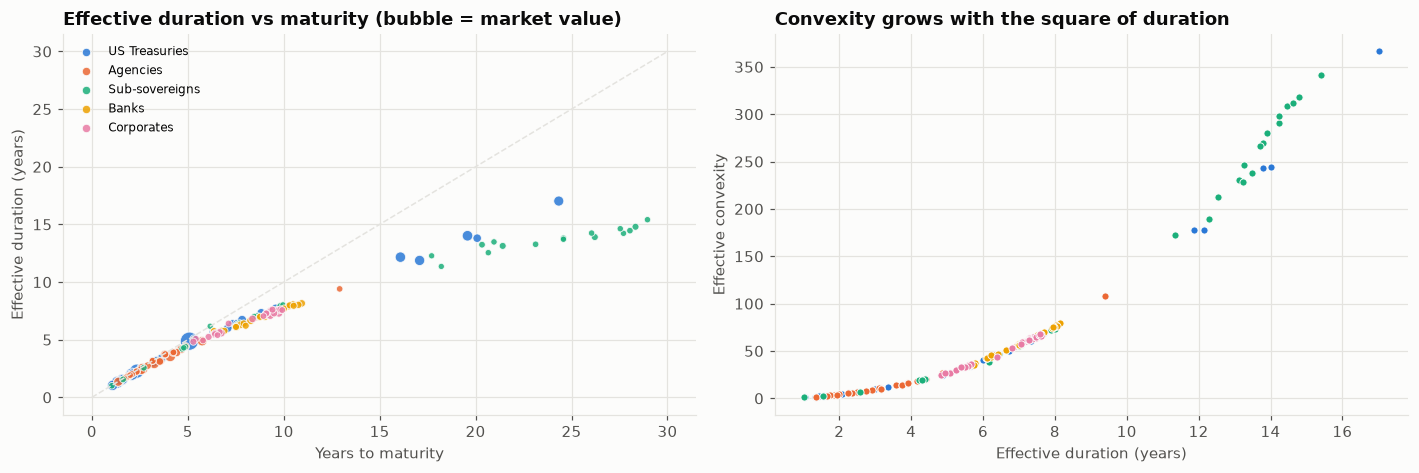

In [9]:
# --- Chart 1: duration and convexity across the portfolio
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for sleeve in SLEEVE_TARGETS:
    g = sens[sens["sleeve"] == sleeve]
    axes[0].scatter(
        g["years_to_maturity"],
        g["effective_dur"],
        s=10 + g["market_value"] / 1e6 * 2.5,
        color=SLEEVE_COLORS[sleeve],
        alpha=0.85,
        edgecolor=SURFACE,
        lw=0.6,
        label=sleeve,
    )
    axes[1].scatter(
        g["effective_dur"],
        g["effective_convexity"],
        s=22,
        color=SLEEVE_COLORS[sleeve],
        edgecolor=SURFACE,
        lw=0.6,
        label=sleeve,
    )
axes[0].plot([0, 30], [0, 30], color=GRID, lw=1, ls="--")
axes[0].set_title("Effective duration vs maturity (bubble = market value)")
axes[0].set_xlabel("Years to maturity")
axes[0].set_ylabel("Effective duration (years)")
leg = axes[0].legend(fontsize=8)
# equal-size legend markers, whatever the bubble sizes
for handle in leg.legend_handles:
    handle.set_sizes([30])
axes[1].set_title("Convexity grows with the square of duration")
axes[1].set_xlabel("Effective duration (years)")
axes[1].set_ylabel("Effective convexity")
plt.tight_layout()
save_fig(fig, "01_duration_and_convexity")
plt.show()

### 6.1 Where along the curve is the risk?

Key-rate DV01 by sleeve and tenor. This is the picture a hedger works from: Treasuries and agencies concentrate risk in the 2–7 year bucket, while the long munis put most of their risk at 20 years.

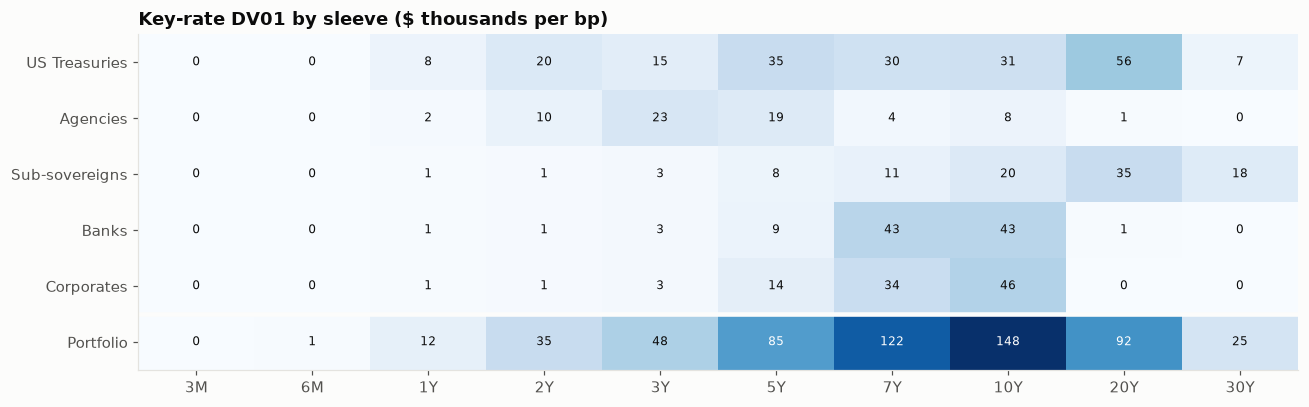

In [10]:
# $k per bp
kr01_sleeve = (
    kr01_df.groupby(sens["sleeve"]).sum().reindex(SLEEVE_TARGETS) / 1e3
)
kr01_sleeve.loc["Portfolio"] = kr01_sleeve.sum()

fig, ax = plt.subplots(figsize=(12, 3.8))
vals = kr01_sleeve.values
im = ax.imshow(vals, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(KEY_TENORS)), kr01_sleeve.columns)
ax.set_yticks(range(len(kr01_sleeve)), kr01_sleeve.index)
for (r, c), v in np.ndenumerate(vals):
    ax.text(
        c,
        r,
        f"{v:,.0f}",
        ha="center",
        va="center",
        fontsize=8,
        color="white" if v > vals.max() * 0.55 else INK,
    )
ax.axhline(len(SLEEVE_TARGETS) - 0.5, color=SURFACE, lw=3)
ax.set_title("Key-rate DV01 by sleeve ($ thousands per bp)")
ax.grid(False)
plt.tight_layout()
save_fig(fig, "02_kr01_heatmap")
plt.show()

## 7. Which curve moves are realistic? PCA of daily Treasury changes

PCA on 10 years of daily changes (bp) at the key tenors. We keep the loadings in **bp per one-standard-deviation day** (eigenvector × √eigenvalue), so a "2σ monthly slope scenario" is simply twice the slope loading scaled by √21.

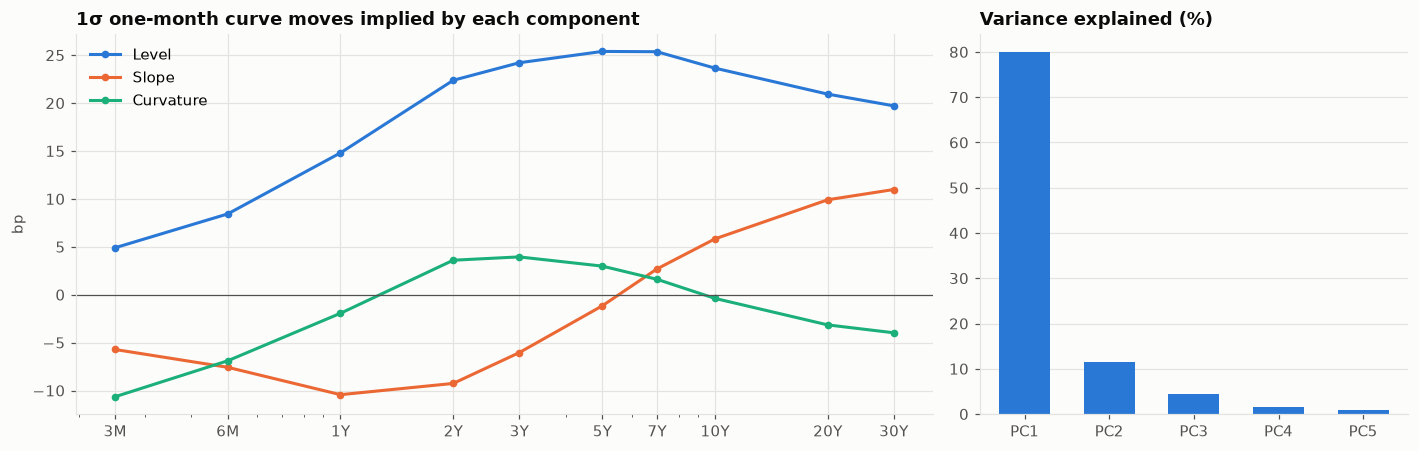

Variance explained: Level 79.9%, Slope 11.4%, Curvature 4.5%


In [11]:
pca = PCA(n_components=len(KEY_TENORS)).fit(daily_changes_bp.values)
explained = pca.explained_variance_ratio_
# bp per 1σ day
loadings_bp = pca.components_[:3].T * np.sqrt(pca.explained_variance_[:3])

# Readable signs: level positive, slope rising with maturity, curvature
# positive in the belly
if loadings_bp[:, 0].mean() < 0:
    loadings_bp[:, 0] *= -1
if loadings_bp[-1, 1] < loadings_bp[0, 1]:
    loadings_bp[:, 1] *= -1
if loadings_bp[np.argmin(np.abs(KEY_TENORS - 5)), 2] < 0:
    loadings_bp[:, 2] *= -1
FACTORS = ["Level", "Slope", "Curvature"]

fig, axes = plt.subplots(
    1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [2, 1]}
)
for i, name in enumerate(FACTORS):
    axes[0].plot(
        KEY_TENORS,
        loadings_bp[:, i] * np.sqrt(HORIZON_DAYS),
        marker="o",
        ms=4,
        color=PALETTE[i],
        label=name,
    )
axes[0].axhline(0, color=INK_2, lw=0.8)
axes[0].set_xscale("log")
axes[0].set_xticks(KEY_TENORS, [tenor_label(t) for t in KEY_TENORS])
axes[0].set_title("1σ one-month curve moves implied by each component")
axes[0].set_ylabel("bp")
axes[0].legend()
axes[1].bar(range(1, 6), explained[:5] * 100, color=PALETTE[0], width=0.6)
axes[1].set_xticks(range(1, 6), [f"PC{i}" for i in range(1, 6)])
axes[1].set_title("Variance explained (%)")
axes[1].grid(axis="x", visible=False)
plt.tight_layout()
save_fig(fig, "03_pca_components")
plt.show()
print(
    "Variance explained: "
    + ", ".join(f"{n} {e:.1%}" for n, e in zip(FACTORS, explained[:3]))
)

## 8. Scenario P&L: full revaluation vs the approximations

Each scenario is a shift of the zero curve defined at the key tenors and interpolated in between. For every scenario we compare:

- **Full revaluation:** every bond repriced on the shifted curve (the truth);
- **Key-rate approximation:** $-\sum_k \text{KR01}_k\,\Delta y_k$;
- **Key-rate + convexity:** adds the second-order term $\tfrac12 C\,P\,(\overline{\Delta y})^2$, with $\overline{\Delta y}$ the KR01-weighted average shift;
- **Duration only:** $-\text{DV01} \times \Delta y(D)$, where $\Delta y(D)$ is the shift at the portfolio's duration point (the usual one-number shortcut);
- **Duration + convexity:** the same shortcut plus $\tfrac12 C\,P\,\Delta y(D)^2$.

Scenarios cover the regulatory-style parallel and twist shocks, PCA-based ±2σ one-month moves, and the two worst historical periods for this portfolio over the last ten years.

In [12]:
def linear_twist(short_bp, long_bp):
    """
    Shift that moves linearly in log-maturity from short_bp at 3M to long_bp at
    30Y.
    """
    w = (np.log(KEY_TENORS) - np.log(KEY_TENORS[0])) / (
        np.log(KEY_TENORS[-1]) - np.log(KEY_TENORS[0])
    )
    return short_bp + (long_bp - short_bp) * w


# hump centred on 5Y
belly = np.exp(-0.5 * ((np.log(KEY_TENORS) - np.log(5)) / 0.7) ** 2)
scale_m = np.sqrt(HORIZON_DAYS)
SCENARIOS = {
    "Parallel +100": np.full(len(KEY_TENORS), 100.0),
    "Parallel −100": np.full(len(KEY_TENORS), -100.0),
    "Parallel +200": np.full(len(KEY_TENORS), 200.0),
    "Bear steepener (+0/+100)": linear_twist(0, 100),
    "Bull flattener (0/−100)": linear_twist(0, -100),
    "Short rates +150 (Basel)": linear_twist(150, 0),
    "Butterfly (belly +50)": 50 * belly,
    "PCA level +2σ (1M)": 2 * scale_m * loadings_bp[:, 0],
    "PCA slope +2σ (1M)": 2 * scale_m * loadings_bp[:, 1],
    "PCA curvature +2σ (1M)": 2 * scale_m * loadings_bp[:, 2],
}

# Historical: the worst 1-day and worst 21-day moves for this portfolio
# (first-order loss, then full reval)
kr01_total = kr01.sum(axis=0)
loss_1d = daily_changes_bp.values @ kr01_total
moves_21 = history.diff(HORIZON_DAYS).dropna() * 100
loss_21 = moves_21.values @ kr01_total
SCENARIOS[
    f"Worst day ({daily_changes_bp.index[loss_1d.argmax()]:%d %b %Y})"
] = daily_changes_bp.values[loss_1d.argmax()]
SCENARIOS[f"Worst month (to {moves_21.index[loss_21.argmax()]:%d %b %Y})"] = (
    moves_21.values[loss_21.argmax()]
)


def full_reval(shift_bp):
    """
    Exact portfolio P&L for a zero-curve shift given at the key tenors (bp).
    """
    shift = lambda t: np.interp(t, KEY_TENORS, shift_bp) * 1e-4
    pnl = 0.0
    for _, b in portfolio.iterrows():
        s = b["z_spread_bp"] / 1e4
        pnl += (
            (
                price_from_curve(b["times"], b["amounts"], s, shift)
                - price_from_curve(b["times"], b["amounts"], s)
            )
            * b["face"]
            / 100
        )
    return pnl


port_value = portfolio["market_value"].sum()
port_conv = np.average(
    sens["effective_convexity"], weights=sens["market_value"]
)
port_dur = by_sleeve.loc["Portfolio", "effective_dur"]
convexity_term = (
    lambda dy_bp: 0.5 * port_conv * port_value * (dy_bp / 1e4) ** 2
)
rows = []
for name, shift_bp in SCENARIOS.items():
    # KR01-weighted average move
    kr_shift = np.dot(kr01_total, shift_bp) / kr01_total.sum()
    # move at the duration point
    dur_shift = np.interp(port_dur, KEY_TENORS, shift_bp)
    key_rate = -np.dot(kr01_total, shift_bp)
    rows.append({
        "scenario": name,
        "shift_at_duration_bp": dur_shift,
        "full_reval_$mm": full_reval(shift_bp) / 1e6,
        "key_rate_$mm": key_rate / 1e6,
        "key_rate_convexity_$mm": (key_rate + convexity_term(kr_shift)) / 1e6,
        "duration_$mm": -TOTAL_DV01 * dur_shift / 1e6,
        "dur_convexity_$mm": (
            -TOTAL_DV01 * dur_shift + convexity_term(dur_shift)
        ) / 1e6,
    })
scen = pd.DataFrame(rows).set_index("scenario")
for c in ["key_rate", "key_rate_convexity", "duration", "dur_convexity"]:
    scen[f"{c}_error_%"] = (
        scen[f"{c}_$mm"] / scen["full_reval_$mm"] - 1
    ) * 100
scen.round(2)

,shift_at_duration_bp,full_reval_$mm,key_rate_$mm,key_rate_convexity_$mm,duration_$mm,dur_convexity_$mm,key_rate_error_%,key_rate_convexity_error_%,duration_error_%,dur_convexity_error_%
scenario,,,,,,,,,,
Parallel +100,100.00,-54.23,-56.88,-54.08,-56.91,-54.11,4.88,-0.27,4.93,-0.22
Parallel −100,-100.00,59.83,56.88,59.68,56.91,59.70,-4.94,-0.27,-4.89,-0.22
Parallel +200,200.00,-103.59,-113.76,-102.57,-113.81,-102.63,9.81,-0.99,9.86,-0.93
Bear steepener (+0/+100),65.00,-38.78,-40.55,-39.13,-36.99,-35.81,4.56,0.89,-4.62,-7.67
Bull flattener (0/−100),-65.00,42.54,40.55,41.97,36.99,38.17,-4.67,-1.32,-13.04,-10.26
Short rates +150 (Basel),52.50,-24.16,-24.49,-23.97,-29.87,-29.10,1.35,-0.79,23.63,20.44
Butterfly (belly +50),48.12,-17.32,-17.54,-17.27,-27.38,-26.73,1.26,-0.28,58.11,54.37
PCA level +2σ (1M),50.76,-26.06,-26.62,-26.01,-28.88,-28.16,2.15,-0.20,10.83,8.07
PCA slope +2σ (1M),0.33,-3.00,-3.06,-3.06,-0.19,-0.19,2.03,1.76,-93.70,-93.71


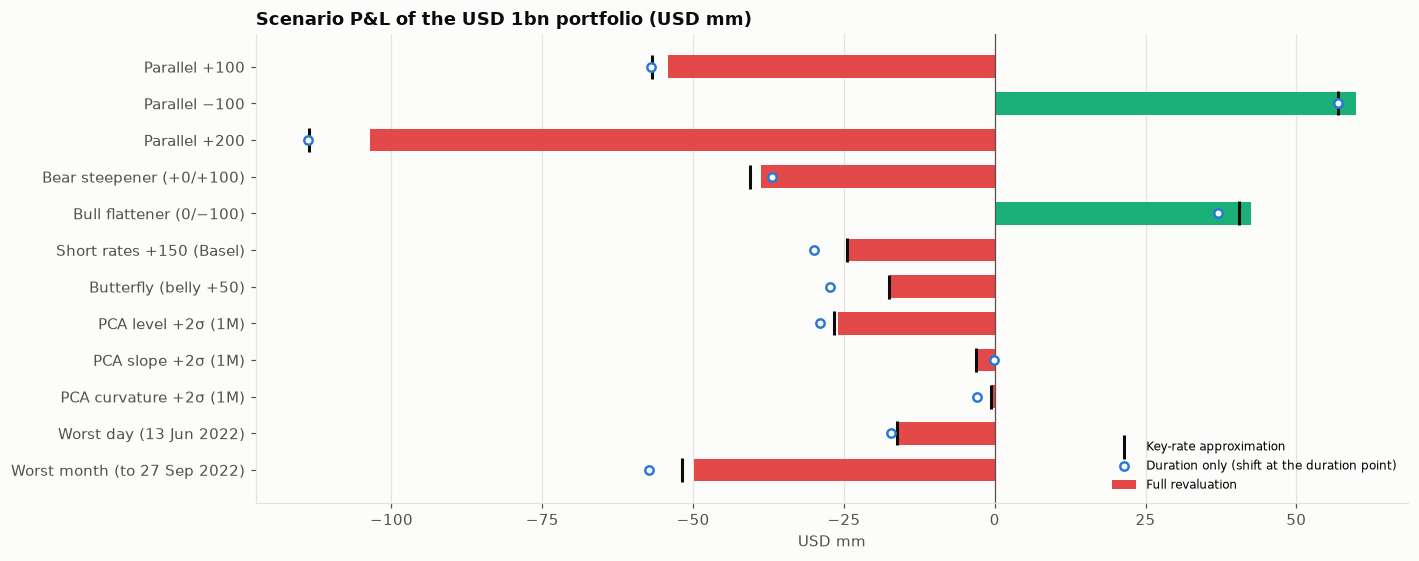

In [13]:
# --- Chart 4: scenario P&L, full revaluation vs approximations
fig, ax = plt.subplots(figsize=(13, 5.2))
y = np.arange(len(scen))
ax.barh(
    y,
    scen["full_reval_$mm"],
    color=[
        STATUS["red"] if v < 0 else STATUS["green"]
        for v in scen["full_reval_$mm"]
    ],
    height=0.62,
    label="Full revaluation",
)
ax.scatter(
    scen["key_rate_$mm"],
    y,
    marker="|",
    s=260,
    color=INK,
    lw=2,
    label="Key-rate approximation",
    zorder=3,
)
ax.scatter(
    scen["duration_$mm"],
    y,
    marker="o",
    s=30,
    facecolor=SURFACE,
    edgecolor=PALETTE[0],
    lw=1.6,
    label="Duration only (shift at the duration point)",
    zorder=3,
)
ax.set_yticks(y, scen.index)
ax.invert_yaxis()
ax.axvline(0, color=INK_2, lw=0.8)
ax.set_title("Scenario P&L of the USD 1bn portfolio (USD mm)")
ax.set_xlabel("USD mm")
ax.legend(loc="lower right", fontsize=8)
ax.grid(axis="y", visible=False)
plt.tight_layout()
save_fig(fig, "04_scenario_pnl")
plt.show()

### 8.1 Where the duration approximation breaks down

Parallel shifts from −300 to +300 bp. Duration alone overstates losses when rates rise and understates gains when they fall, the textbook convexity effect. The second-order term closes most of the gap; what remains comes from higher-order terms.

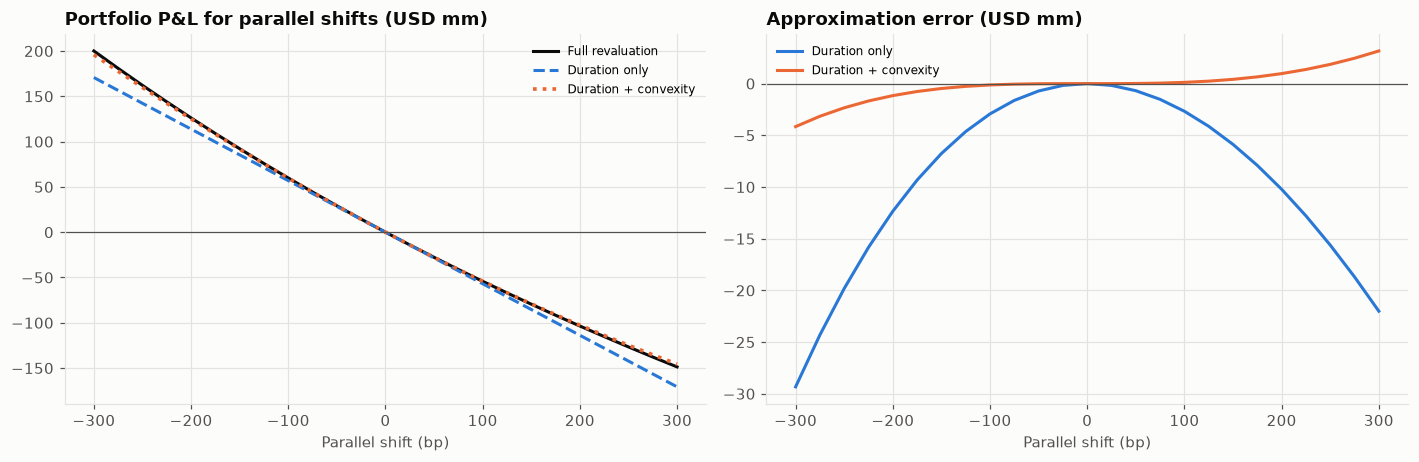

At +200 bp: full -103.6mm · duration -113.8mm (error -10.2mm) · duration+convexity error +0.97mm


In [14]:
shocks = np.arange(-300, 301, 25)
full_curve = (
    np.array([full_reval(np.full(len(KEY_TENORS), float(x))) for x in shocks])
    / 1e6
)
dur_curve = -TOTAL_DV01 * shocks / 1e6
dc_curve = dur_curve + 0.5 * port_conv * port_value * (shocks / 1e4) ** 2 / 1e6

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].plot(shocks, full_curve, color=INK, label="Full revaluation")
axes[0].plot(
    shocks, dur_curve, color=PALETTE[0], ls="--", label="Duration only"
)
axes[0].plot(
    shocks,
    dc_curve,
    color=PALETTE[1],
    ls=":",
    lw=2.4,
    label="Duration + convexity",
)
axes[0].axhline(0, color=INK_2, lw=0.8)
axes[0].set_title("Portfolio P&L for parallel shifts (USD mm)")
axes[0].set_xlabel("Parallel shift (bp)")
axes[0].legend(fontsize=8)
axes[1].plot(
    shocks, dur_curve - full_curve, color=PALETTE[0], label="Duration only"
)
axes[1].plot(
    shocks,
    dc_curve - full_curve,
    color=PALETTE[1],
    label="Duration + convexity",
)
axes[1].axhline(0, color=INK_2, lw=0.8)
axes[1].set_title("Approximation error (USD mm)")
axes[1].set_xlabel("Parallel shift (bp)")
axes[1].legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "05_taylor_error")
plt.show()

i200 = list(shocks).index(200)
print(
    f"At +200 bp: full {full_curve[i200]:,.1f}mm · duration"
    f" {dur_curve[i200]:,.1f}mm (error"
    f" {dur_curve[i200]-full_curve[i200]:+.1f}mm) · duration+convexity error"
    f" {dc_curve[i200]-full_curve[i200]:+.2f}mm"
)

In [15]:
# --- Export the report tables
pd.concat([sens, kr01_df.add_prefix("KR01_")], axis=1).to_csv(
    OUT_DIR / "bond_sensitivities.csv", index=False
)
by_sleeve.to_csv(OUT_DIR / "sensitivities_by_sleeve.csv")
scen.to_csv(OUT_DIR / "scenario_pnl.csv")
print(
    "Saved outputs/bond_sensitivities.csv, sensitivities_by_sleeve.csv,"
    " scenario_pnl.csv"
)

Saved outputs/bond_sensitivities.csv, sensitivities_by_sleeve.csv, scenario_pnl.csv


## 9. Reading the results and limitations

**What to take away**

- **Duration is a good first answer for parallel moves of normal size.** At ±100 bp the duration-only estimate is off by about 5%, at +200 bp by about 10%, always on the pessimistic side for rising rates. Adding convexity brings the error below 1%.
- **For curve-shape scenarios the one-number shortcut breaks down.** Reading the move at the duration point misjudges steepeners, flatteners and the Basel short-rate shock, because the portfolio's risk is spread from 2 to 20 years. The key-rate vector plus convexity reproduces full revaluation within 2% in every scenario.

**PCA scenarios show what is plausible.** A 2σ one-month level move is around 45–50 bp, roughly half the regulatory ±100 bp. The 2σ slope and curvature moves cost very little because this long-only portfolio is overwhelmingly a level bet. The worst month of the last decade (September 2022) cost about USD 50 mm, the equivalent of a +90 bp parallel shift.

- **Risk concentration.** The heatmap shows where the DV01 sits by tenor and sleeve. It is the input for a swap hedge and for the IRRBB view.

**Limitations**

- **Rate risk only.** Z-spreads are held fixed; spread duration and CS01 are not measured here.
- **Callable munis are priced to maturity**, which overstates their duration and ignores negative convexity. An option-adjusted measure needs a short-rate model (a Hull–White engine could provide one).
- **Constant-maturity history.** The PCA uses FRED CMT par yields as a proxy for zero-rate moves, a standard approximation at daily horizons.

## References

### Finance and regulation

- Ho, T. S. Y. (1992). Key rate durations: Measures of interest rate risks. *The Journal of Fixed Income, 2*(2), 29–44. https://doi.org/10.3905/jfi.1992.408049
- Litterman, R., & Scheinkman, J. (1991). Common factors affecting bond returns. *The Journal of Fixed Income, 1*(1), 54–61. https://doi.org/10.3905/jfi.1991.692347
- Tuckman, B., & Serrat, A. (2022). *Fixed income securities: Tools for today's markets* (4th ed.). Wiley. https://doi.org/10.1002/9781119835622
- Golub, B. W., & Tilman, L. M. (1997). Measuring yield curve risk using principal components analysis, value at risk, and key rate durations. *The Journal of Portfolio Management, 23*(4), 72–84. https://doi.org/10.3905/jpm.1997.409612
- Redington, F. M. (1952). Review of the principles of life-office valuations. *Journal of the Institute of Actuaries, 78*(3), 286–340. https://doi.org/10.1017/S0020268100052811

### Machine learning and deep learning

- Jolliffe, I. T., & Cadima, J. (2016). Principal component analysis: A review and recent developments. *Philosophical Transactions of the Royal Society A, 374*(2065), 20150202. https://doi.org/10.1098/rsta.2015.0202